In [8]:
# Cellule 1: Imports et hyper-paramètres
import os
import pandas as pd
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

from sklearn.metrics import mean_absolute_error, r2_score

import matplotlib.pyplot as plt
from IPython.display import clear_output
%matplotlib inline

# Hyper‐paramètres
CSV_PATH    = "dataset_project_iapr2025/train.csv"
BG_PATH     = "dataset_project_iapr2025/train/background.csv"
TRAIN_DIR   = "dataset_project_iapr2025/train/"
TEST_DIR    = "dataset_project_iapr2025/test/"
MODEL_PATH  = "choco_count_model.pth"
OUTPUT_CSV  = "submission.csv"
IMG_SIZE    = 160
BATCH_SIZE  = 32
LR          = 1e-3
WIDTH_MULT  = 2.5
N_EPOCHS    = 50
EMB_DIM     = 32     # dimension de l'embedding issu des features
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cuda


In [9]:
# Cellule 2: Dataset intégrant toutes les features de background.csv
class ChocolateCountDatasetBG(Dataset):
    def __init__(self, csv_path, bg_path, img_dir, img_size=160, train=True):
        # Lecture des deux CSV et fusion sur 'id'
        df_counts = pd.read_csv(csv_path)
        df_bg     = pd.read_csv(bg_path)
        df        = df_counts.merge(df_bg, on='id', how='left')

        # IDs et targets (comptages)
        self.ids    = df['id'].astype(str).tolist()
        self.counts = df_counts.iloc[:,1:].values.astype(np.float32)

        # Sélection des colonnes numeriques du background (hors 'id','background')
        self.bg_cols = [
            'mean_red','mean_green','mean_blue','mean_gray',
            'std_gray','std_contours','s_mean','s_std',
            'v_mean','v_std','lap_var','dark_ratio','bright_ratio',
            'lbp_0','lbp_1','lbp_2','lbp_3',
            'edge_ratio','entropy_mean','entropy_std'
        ]
        feats = df[self.bg_cols].values.astype(np.float32)
        # normalisation z-score
        self.feat_mean = feats.mean(axis=0, keepdims=True)
        self.feat_std  = feats.std(axis=0, keepdims=True) + 1e-6
        self.bg_feats  = (feats - self.feat_mean) / self.feat_std

        self.classes = list(df_counts.columns[1:])
        self.img_dir = img_dir
        self.train   = train

        # transformations
        aug = [
            transforms.Resize((img_size,img_size)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(20),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
        ]
        noaug = [
            transforms.Resize((img_size,img_size)),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
        ]
        self.transform = transforms.Compose(aug if train else noaug)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        # chargement de l'image
        img = Image.open(os.path.join(self.img_dir, f"L{img_id}.JPG")).convert("RGB")
        x   = self.transform(img)
        y   = torch.from_numpy(self.counts[idx])
        bgf = torch.from_numpy(self.bg_feats[idx])  # vecteur bg normalisé
        return x, bgf, y


In [10]:
# Cellule 3: Module FiLM + InvertedResidualFiLM
class FiLM(nn.Module):
    def __init__(self, num_features, emb_dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(emb_dim, num_features * 2),
            nn.ReLU(inplace=True)
        )

    def forward(self, x, emb):
        B, C, H, W = x.shape
        gamma_beta = self.mlp(emb)                # (B, 2*C)
        gamma, beta = gamma_beta.chunk(2, dim=1)  # chaque (B, C)
        gamma = gamma.view(B, C, 1, 1)
        beta  = beta.view (B, C, 1, 1)
        return gamma * x + beta

class InvertedResidualFiLM(nn.Module):
    def __init__(self, in_c, out_c, stride, expand_ratio, emb_dim):
        super().__init__()
        hidden     = in_c * expand_ratio
        self.use_res = (stride == 1 and in_c == out_c)
        layers = []
        # expansion
        if expand_ratio != 1:
            layers += [
                nn.Conv2d(in_c, hidden, 1, bias=False),
                nn.BatchNorm2d(hidden), nn.ReLU6(inplace=True),
            ]
        # depthwise + projection
        layers += [
            nn.Conv2d(hidden, hidden, 3, stride, 1, groups=hidden, bias=False),
            nn.BatchNorm2d(hidden), nn.ReLU6(inplace=True),
            nn.Conv2d(hidden, out_c, 1, bias=False),
            nn.BatchNorm2d(out_c),
        ]
        self.block = nn.Sequential(*layers)
        self.film  = FiLM(num_features=out_c, emb_dim=emb_dim)

    def forward(self, x, emb):
        out = self.block(x)
        out = self.film(out, emb)
        return x + out if self.use_res else out


In [11]:
# Cellule 4: MobileNetV2 conditionné sur les features continues du background
class MobileNetV2_FiLM_BG(nn.Module):
    def __init__(self, n_classes, width_mult, num_bg_feats, emb_dim=32):
        super().__init__()
        # MLP pour projeter bg_feats → emb_dim
        self.bg_mlp = nn.Sequential(
            nn.Linear(num_bg_feats, emb_dim*2),
            nn.ReLU(inplace=True),
            nn.Linear(emb_dim*2, emb_dim)
        )

        # couche d'entrée
        inp = int(32 * width_mult)
        self.initial = nn.Sequential(
            nn.Conv2d(3, inp, 3, 2, 1, bias=False),
            nn.BatchNorm2d(inp), nn.ReLU6(inplace=True)
        )

        # construction des blocs FiLM
        cfgs = [(1,16,1,1),(6,24,2,2),(6,32,3,2),
                (6,64,4,2),(6,96,3,1),(6,160,3,2),(6,320,1,1)]
        self.blocks = nn.ModuleList()
        for t, c, n, s in cfgs:
            out = int(c * width_mult)
            for i in range(n):
                stride = s if i == 0 else 1
                self.blocks.append(
                    InvertedResidualFiLM(inp, out, stride, expand_ratio=t, emb_dim=emb_dim)
                )
                inp = out

        # projection finale + pooling global
        last = int(1280 * width_mult) if width_mult > 1.0 else 1280
        self.final_conv = nn.Sequential(
            nn.Conv2d(inp, last, 1, bias=False),
            nn.BatchNorm2d(last), nn.ReLU6(inplace=True),
            nn.AdaptiveAvgPool2d(1)
        )

        # classifieur sur [feat + emb_dim]
        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(last + emb_dim, n_classes)
        )

    def forward(self, x, bg_feats):
        # projeter et récupérer l'embedding
        emb = self.bg_mlp(bg_feats)            # (B, emb_dim)
        # convolutions
        x = self.initial(x)
        for block in self.blocks:
            x = block(x, emb)
        f = self.final_conv(x).view(x.size(0), -1)  # (B, last)
        # concat features + emb
        cat = torch.cat([f, emb], dim=1)       # (B, last+emb_dim)
        return self.classifier(cat)


In [12]:
# Cellule 5: préparation des DataLoaders
ds = ChocolateCountDatasetBG(CSV_PATH, BG_PATH, TRAIN_DIR, IMG_SIZE, train=True)
n = len(ds)
train_ds, val_ds = torch.utils.data.random_split(ds, [int(0.8*n), n-int(0.8*n)])
val_ds.dataset.train = False

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


In [13]:
# Cellule 6: métriques et boucles train/val + plot
def mae(preds, target):
    return mean_absolute_error(target.numpy(), preds.numpy())

def r2(preds, target):
    return r2_score(target.numpy(), preds.numpy())

def train_epoch(model, optimizer, criterion, loader, device):
    model.train()
    total_loss = total_mae = total_r2 = 0
    n = 0
    for x, bgf, y in tqdm(loader, desc="Train", leave=False):
        x, bgf, y = x.to(device), bgf.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x, bgf)
        loss = criterion(out, y)
        loss.backward(); optimizer.step()
        bs = x.size(0)
        total_loss += loss.item()*bs
        with torch.no_grad():
            preds, targ = out.cpu(), y.cpu()
            total_mae += mae(preds, targ)*bs
            total_r2  += r2(preds, targ)*bs
        n += bs
    return total_loss/n, total_mae/n, total_r2/n

@torch.no_grad()
def validate_epoch(model, criterion, loader, device):
    model.eval()
    total_loss = total_mae = total_r2 = 0
    n = 0
    for x, bgf, y in tqdm(loader, desc="Val  ", leave=False):
        x, bgf, y = x.to(device), bgf.to(device), y.to(device)
        out = model(x, bgf)
        loss = criterion(out, y)
        bs = x.size(0)
        total_loss += loss.item()*bs
        preds, targ = out.cpu(), y.cpu()
        total_mae += mae(preds, targ)*bs
        total_r2  += r2(preds, targ)*bs
        n += bs
    return total_loss/n, total_mae/n, total_r2/n

def plot_training(train_logs, val_logs, names):
    fig, axes = plt.subplots(1, len(names), figsize=(5*len(names),4))
    for i, name in enumerate(names):
        axes[i].plot(train_logs[name], label='train')
        axes[i].plot(val_logs[name],   label='val')
        axes[i].set_title(name); axes[i].set_xlabel('epoch'); axes[i].legend()
    plt.tight_layout(); plt.show()


Epoch 50/50 – train_loss=0.1358, val_loss=1.2056 – train_MAE=0.2669, val_MAE=0.7968 – train_R2=0.7741, val_R2=-0.8079


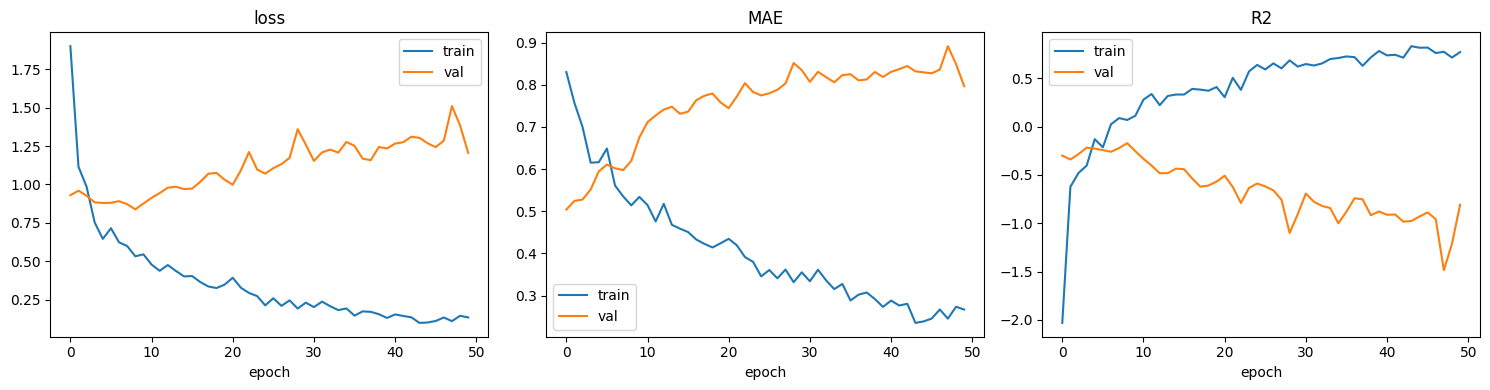

In [14]:
# Cellule 7: instanciation du modèle et boucle d'entraînement
num_bg_feats = len(ds.bg_cols)
n_classes    = len(ds.classes)

model     = MobileNetV2_FiLM_BG(n_classes, WIDTH_MULT, num_bg_feats, emb_dim=EMB_DIM).to(DEVICE)
print("Params:", sum(p.numel() for p in model.parameters()))
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
criterion = nn.MSELoss()

names      = ['loss','MAE','R2']
train_logs = {n:[] for n in names}
val_logs   = {n:[] for n in names}
best_val   = float('inf')

for epoch in range(1, N_EPOCHS+1):
    tr_loss, tr_mae, tr_r2 = train_epoch(model, optimizer, criterion, train_loader, DEVICE)
    vl_loss, vl_mae, vl_r2 = validate_epoch(model, criterion, val_loader, DEVICE)
    # update logs
    train_logs['loss'].append(tr_loss); train_logs['MAE'].append(tr_mae); train_logs['R2'].append(tr_r2)
    val_logs  ['loss'].append(vl_loss);   val_logs  ['MAE'].append(vl_mae);   val_logs  ['R2'].append(vl_r2)
    # clear + affichage
    clear_output(wait=True)
    print(f"Epoch {epoch}/{N_EPOCHS} – "
          f"train_loss={tr_loss:.4f}, val_loss={vl_loss:.4f} – "
          f"train_MAE={tr_mae:.4f}, val_MAE={vl_mae:.4f} – "
          f"train_R2={tr_r2:.4f}, val_R2={vl_r2:.4f}")
    plot_training(train_logs, val_logs, names)
    # sauvegarde
    if vl_loss < best_val:
        best_val = vl_loss
        torch.save(model.state_dict(), MODEL_PATH)


In [ ]:
# Cellule 8: prédiction et génération de submission.csv
# On récupère aussi background.csv du test set
BG_TEST = os.path.join(TEST_DIR, "background.csv")
df_bg_test = pd.read_csv(BG_TEST)

model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

rows = []
for fname in sorted(os.listdir(TEST_DIR)):
    if not fname.lower().endswith(".jpg"): continue
    img_id = fname[1:-4]
    # construire bg_feats pour le test
    row_bg = df_bg_test[df_bg_test.id == int(img_id)][
        ChocolateCountDatasetBG.bg_cols
    ].values.astype(np.float32)
    # normalisation avec les stats du train
    bg_feats = (row_bg - ds.feat_mean) / ds.feat_std
    bgf = torch.from_numpy(bg_feats).to(DEVICE)
    # image
    img = Image.open(os.path.join(TEST_DIR, fname)).convert("RGB")
    x   = transform(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = model(x, bgf)
        preds = out[0].cpu().numpy()
    rows.append([img_id, *preds.tolist()])

submission = pd.DataFrame(rows, columns=["id"] + ds.classes)
submission.to_csv(OUTPUT_CSV, index=False)
print("✅ Submission saved to", OUTPUT_CSV)
submission.head()
